# Predicción de Abandono de Clientes (Telco Customer Churn)
## Notebook 1 de 2 Comprensión de los datos, EDA y preparación

**MLY1101 Machine Learning | Caso A | Evaluación Parcial N°2**

Este notebook cubre las fases 1 a 3 de CRISP-DM (comprensión del negocio, comprensión de los datos y preparación). Es la versión de la EP1 **corregida con la retroalimentación del docente**:

| Comentario del docente (EP1) | Dónde se aborda |
|---|---|
| Origen de los datos: empresa, años, país, quién ha modelado estos datos y qué concluyó | Sección 2 |
| G1: porcentajes y etiquetas de ejes más claras | Sección 5.1 |
| G2: conclusiones respaldadas con métricas (media, mediana, moda, var, etc.) | Sección 5.2 |
| G3: un gráfico por variable, títulos/etiquetas claros, mejor tipo de gráfico | Sección 5.3 |
| G4: usar la correlación adecuada (Pearson, Spearman, etc.) | Sección 5.4 |
| Escalado: Standard solo para datos simétricos; Robust para asimetría; MinMax para uniformes | Sección 6.4 |
| Sesgos: comparar primer y último decil | Sección 5.5 y Sección 7 |

El modelamiento (supervisado y no supervisado) y la evaluación están en `02_Modelamiento_Churn.ipynb`.

## 1. Importación de librerías

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
from scipy.stats.contingency import association
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titleweight": "bold"})

RANDOM_STATE = 42
COLOR_NO, COLOR_SI = "#2a78d6", "#eb6834"   # No abandona / Abandona
IMG = "../images/"

## 2. Fuente de los datos

| Pregunta | Respuesta |
|---|---|
| **¿Quién los publica?** | IBM, como *dataset* de muestra del producto **IBM Cognos Analytics** (versión 11.1.3+), publicado por el equipo *Samples Team* de IBM el 11-07-2019. |
| **¿Qué empresa?** | Una **compañía de telecomunicaciones ficticia**. IBM no nombra una empresa real: los datos son de muestra, creados para demostración. |
| **¿Qué país?** | **Estados Unidos, estado de California.** |
| **¿Qué período?** | Un trimestre fiscal: **Q3**. IBM **no informa el año**. |
| **¿Qué contiene?** | 7.043 clientes con servicios de telefonía fija e Internet. |
| **¿De dónde se descargó?** | Kaggle, *Telco Customer Churn* (usuario *blastchar*), que redistribuye la versión de 21 columnas. El archivo de este proyecto es `data/Telco_Customer_Churn_Dataset.csv`. |

Cita textual de IBM: *"a fictional telco company that provided home phone and Internet services to 7043 customers in California in Q3"*.

> **Consecuencia para el proyecto:** al ser datos de una empresa ficticia, los patrones sirven para practicar y validar la metodología, pero **no** describen el mercado chileno ni una empresa real. Esto se retoma en la evaluación de sesgos (sesgo de representación).

**¿Quién ha construido modelos predictivos con estos datos y qué concluyó?**

| Estudio | Modelos | Resultado reportado | Conclusión |
|---|---|---|---|
| Zhu (2023), *Customer Churn Prediction Based on Big Data and Machine Learning Approaches*, ICFIED 2023, Atlantis Press | LightGBM, Regresión Logística, Random Forest | Reg. Logística: recall 0,84, F1 0,65, accuracy 0,75, AUC 78%. Random Forest: accuracy 0,79 pero recall 0,46 | La Regresión Logística es la más adecuada para detectar a quienes se van; RF tiene mejor accuracy pero detecta menos churn por el desbalance. |
| Aryani y Pratama (2026), JSI Universitas Suryadarma, vol. 13(2) | Regresión Logística, SVM (CV estratificada k=5) | Reg. Logística: accuracy 80,70%; SVM: 79,28% | La Regresión Logística es más estable; las variables más influyentes son tenure, MonthlyCharges, tipo de contrato y tipo de internet. |
| Wanda (2024), tesis MSc, Strathmore University | Reg. Logística, Naive Bayes, KNN, Random Forest, CatBoost | Reg. Logística: recall 80% | Se eligió la Regresión Logística por su recall y se usaron sus coeficientes para sugerir acciones correctivas. |

**Lo que se toma de estos antecedentes:** (1) la *accuracy* sola es engañosa con este desbalance (el RF de Zhu tiene la mejor accuracy y el peor recall), por eso el KPI principal es el **recall**; (2) la Regresión Logística es una línea de referencia competitiva y explicable; (3) las variables clave reportadas (tenure, cargos, contrato, internet) se contrastan con nuestro EDA.

**Herramientas colaborativas:** Git/GitHub (repositorio del equipo, historial de *commits* por integrante) y Jupyter Notebook (entorno reproducible). Ver README.

## 3. Problema de negocio, objetivos y KPIs

**Problema:** la empresa pierde ingresos recurrentes cada vez que un cliente da de baja el servicio. Se busca **anticipar qué clientes tienen mayor probabilidad de abandonar** para activar campañas de retención focalizadas.

**KPIs:**
- **Tasa de churn (%)**: clientes que abandonan / total de clientes.
- **Recall**: % de los clientes que se van que el modelo detecta a tiempo (KPI más crítico).
- **Precisión**: % de los clientes marcados como riesgo que efectivamente se van.
- **Costo evitado**: ingreso mensual de los clientes que se iban y que el modelo logra identificar.

## 4. Carga y comprensión inicial de los datos

In [2]:
df = pd.read_csv("../data/Telco_Customer_Churn_Dataset.csv")
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Dimensiones: 7043 filas x 21 columnas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Diccionario resumido: tipo y valores posibles de cada variable
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "ejemplos": [df[c].unique()[:4].tolist() for c in df.columns],
})
resumen

,tipo,n_unicos,ejemplos
customerID,str,7043,"[7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW]"
gender,str,2,"[Female, Male]"
SeniorCitizen,int64,2,"[0, 1]"
Partner,str,2,"[Yes, No]"
Dependents,str,2,"[No, Yes]"
tenure,int64,73,"[1, 34, 2, 45]"
PhoneService,str,2,"[No, Yes]"
MultipleLines,str,3,"[No phone service, No, Yes]"
InternetService,str,3,"[DSL, Fiber optic, No]"
OnlineSecurity,str,3,"[No, Yes, No internet service]"


### 4.1 Calidad de los datos

Se revisan: valores nulos, valores en blanco, duplicados, tipos incorrectos, valores fuera de rango, valores atípicos (regla IQR) y **consistencia lógica entre columnas**.

In [5]:
print("Nulos por columna (total):", df.isnull().sum().sum())
blancos = (df.astype(str).apply(lambda s: s.str.strip() == "")).sum()
print("\nCeldas en blanco por columna:")
print(blancos[blancos > 0])
print(f"\nFilas duplicadas: {df.duplicated().sum()} | customerID duplicados: {df['customerID'].duplicated().sum()}")

Nulos por columna (total): 0



Celdas en blanco por columna:
TotalCharges    11
dtype: int64



Filas duplicadas: 0 | customerID duplicados: 0


In [6]:
# Los 11 blancos de TotalCharges: ¿quiénes son?
mask_blanco = df["TotalCharges"].str.strip() == ""
df.loc[mask_blanco, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Hallazgo:** `TotalCharges` viene como texto porque 11 registros tienen un espacio en blanco. Los 11 tienen `tenure = 0` (clientes recién ingresados, aún sin facturación acumulada) y ninguno abandonó. Por eso se imputan con **0**, coherente con la lógica de negocio (imputar la media inventaría una facturación que no existe).

In [7]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip().replace("", np.nan))
df["TotalCharges"] = df["TotalCharges"].fillna(0)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# Rangos y valores atípicos (regla de 1,5 x IQR)
filas = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    filas.append([c, df[c].min(), df[c].max(), q1, q3, iqr, n_out])
pd.DataFrame(filas, columns=["variable", "mín", "máx", "Q1", "Q3", "IQR", "atípicos IQR"]).round(2)

,variable,mín,máx,Q1,Q3,IQR,atípicos IQR
0,tenure,0.00,72.00,9.00,55.00,46.00,0
1,MonthlyCharges,18.25,118.75,35.50,89.85,54.35,0
2,TotalCharges,0.00,8684.80,398.55,3786.60,3388.05,0


In [8]:
# Consistencia lógica entre columnas
print("PhoneService = No  <->  MultipleLines = 'No phone service':",
      ((df["PhoneService"] == "No") != (df["MultipleLines"] == "No phone service")).sum(), "inconsistencias")
servicios_internet = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
for c in servicios_internet:
    n = ((df["InternetService"] == "No") != (df[c] == "No internet service")).sum()
    print(f"InternetService = No  <->  {c} = 'No internet service': {n} inconsistencias")

# TotalCharges debería ser aproximadamente tenure x MonthlyCharges
esperado = df["tenure"] * df["MonthlyCharges"]
desvio_rel = ((df["TotalCharges"] - esperado) / esperado.replace(0, np.nan))
print("\nDesviación relativa TotalCharges vs tenure x MonthlyCharges:")
print(desvio_rel.describe().round(3))
print("Clientes con desviación mayor a ±20%:", (desvio_rel.abs() > 0.20).sum())

PhoneService = No  <->  MultipleLines = 'No phone service': 0 inconsistencias
InternetService = No  <->  OnlineSecurity = 'No internet service': 0 inconsistencias
InternetService = No  <->  OnlineBackup = 'No internet service': 0 inconsistencias
InternetService = No  <->  DeviceProtection = 'No internet service': 0 inconsistencias
InternetService = No  <->  TechSupport = 'No internet service': 0 inconsistencias
InternetService = No  <->  StreamingTV = 'No internet service': 0 inconsistencias
InternetService = No  <->  StreamingMovies = 'No internet service': 0 inconsistencias

Desviación relativa TotalCharges vs tenure x MonthlyCharges:


count    7032.000
mean        0.000
std         0.051
min        -0.311
25%        -0.020
50%         0.000
75%         0.020
max         0.573
dtype: float64
Clientes con desviación mayor a ±20%: 59


**Conclusiones de calidad:**
- No hay nulos, duplicados ni `customerID` repetidos. El único problema de tipo/valores fue `TotalCharges` (11 blancos), ya corregido.
- **No hay valores atípicos** según la regla IQR en ninguna variable numérica; todos los valores están en rangos plausibles (tenure 0–72 meses, cargo mensual USD 18,25–118,75).
- Las categorías dependientes son **100% consistentes**: quien no tiene teléfono figura con "No phone service" y quien no tiene internet figura con "No internet service" en los 6 servicios asociados.
- `TotalCharges` coincide con `tenure × MonthlyCharges` (mediana de desviación 0%). Hay 59 clientes con una diferencia mayor a ±20%; se interpretan como **cambios de plan** durante su permanencia (el cargo mensual actual no es el que pagaron siempre), no como errores, por lo que se mantienen.
- **Consecuencia para el modelamiento:** como `TotalCharges` es casi el producto de otras dos variables, es redundante (ver correlación en 5.4).

## 5. Análisis exploratorio (EDA)

### 5.1 Variable objetivo: Churn

       clientes  porcentaje
Churn                      
No         5174       73.46
Yes        1869       26.54


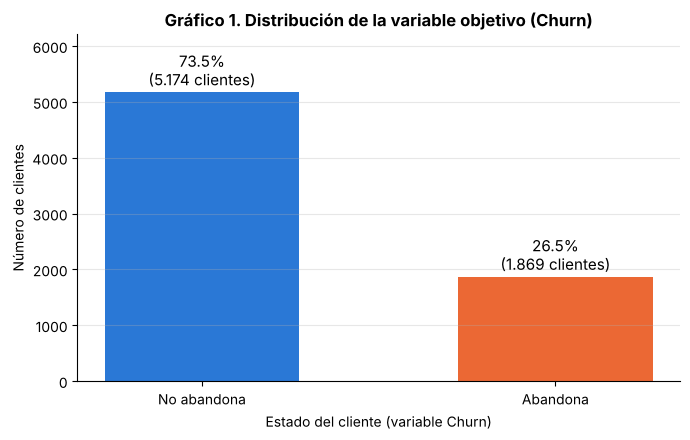

In [9]:
conteo = df["Churn"].value_counts().reindex(["No", "Yes"])
pct = conteo / conteo.sum() * 100
print(pd.DataFrame({"clientes": conteo, "porcentaje": pct.round(2)}))

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(["No abandona", "Abandona"], conteo.values, color=[COLOR_NO, COLOR_SI], width=0.55)
for b, n, p in zip(barras, conteo.values, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 60, f"{p:.1f}%\n({n:,} clientes)".replace(",", "."),
            ha="center", va="bottom", fontsize=11)
ax.set_title("Gráfico 1. Distribución de la variable objetivo (Churn)")
ax.set_xlabel("Estado del cliente (variable Churn)")
ax.set_ylabel("Número de clientes")
ax.set_ylim(0, conteo.max() * 1.2)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(IMG + "g1_distribucion_churn.png", dpi=130); plt.show()

**Observación:** **26,5%** de los clientes abandona (1.869 de 7.043) y 73,5% se queda. La clase está desbalanceada en proporción ≈ 1 : 2,8. Un modelo que diga siempre "No abandona" tendría 73,5% de accuracy y 0% de recall, por eso la evaluación usará recall, precisión y F1.

### 5.2 Variables numéricas vs. Churn

Primero se mide la **forma de la distribución** de cada variable (necesario también para elegir el escalado en 6.4). Luego se compara cada variable entre quienes abandonan y quienes no, con estadísticos descriptivos y una prueba de hipótesis.

In [10]:
forma = pd.DataFrame({
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "asimetría (skew)": df[num_cols].skew(),
    "curtosis (exceso)": df[num_cols].kurt(),
    "p-valor normalidad (D'Agostino)": [stats.normaltest(df[c]).pvalue for c in num_cols],
}).round(3)
forma

,media,mediana,asimetría (skew),curtosis (exceso),p-valor normalidad (D'Agostino)
tenure,32.371,29.00,0.240,-1.387,0.0
MonthlyCharges,64.762,70.35,-0.221,-1.257,0.0
TotalCharges,2279.734,1394.55,0.963,-0.229,0.0


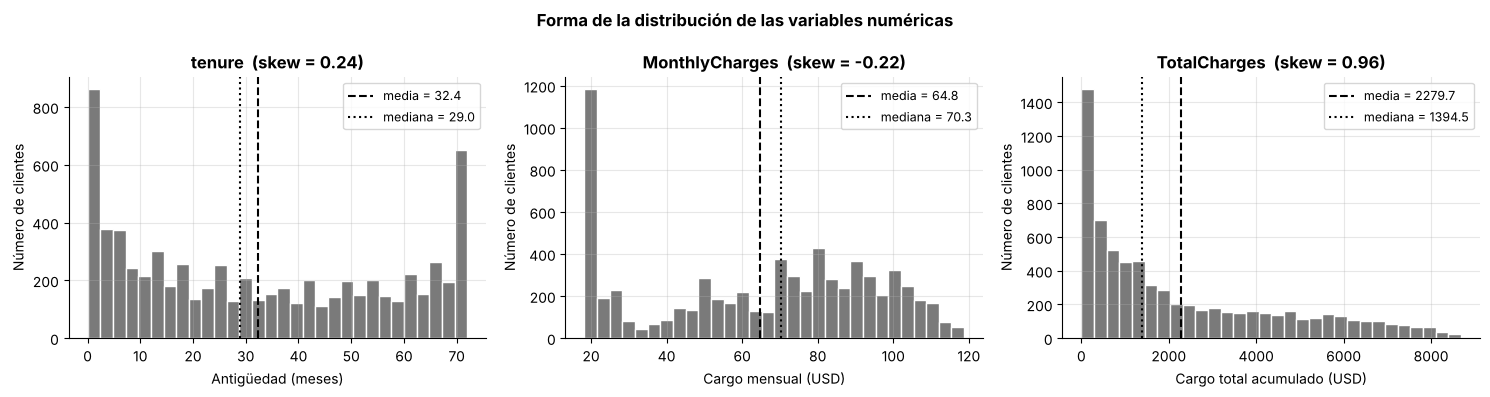

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c, et in zip(axes, num_cols, ["Antigüedad (meses)", "Cargo mensual (USD)", "Cargo total acumulado (USD)"]):
    ax.hist(df[c], bins=30, color="#7a7a7a", edgecolor="white")
    ax.axvline(df[c].mean(), color="black", ls="--", lw=1.5, label=f"media = {df[c].mean():.1f}")
    ax.axvline(df[c].median(), color="black", ls=":", lw=1.5, label=f"mediana = {df[c].median():.1f}")
    ax.set_title(f"{c}  (skew = {df[c].skew():.2f})")
    ax.set_xlabel(et); ax.set_ylabel("Número de clientes"); ax.legend(fontsize=9)
fig.suptitle("Forma de la distribución de las variables numéricas", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "forma_distribuciones.png", dpi=130); plt.show()

**Observación sobre la forma:** ninguna variable es normal (p-valor ≈ 0 en las tres).
- `tenure`: casi simétrica (skew 0,24) pero **aplanada** (curtosis −1,39) con dos picos en los extremos (clientes nuevos y clientes de 72 meses); acotada entre 0 y 72. Se parece más a una distribución uniforme que a una normal.
- `MonthlyCharges`: levemente asimétrica a la izquierda (skew −0,22), aplanada (curtosis −1,26) y **bimodal**: un pico cerca de USD 20 (clientes solo con teléfono) y otro entre USD 70 y 100. Acotada entre 18 y 119.
- `TotalCharges`: **asimétrica a la derecha** (skew 0,96): muchos clientes con poco acumulado y una cola larga de clientes antiguos.

In [12]:
def moda(s):
    return s.mode().iloc[0]

def comparar_grupos(col):
    g = df.groupby("Churn")[col].agg(["count", "mean", "median", moda, "std", "var",
                                       lambda s: s.quantile(0.75) - s.quantile(0.25)])
    g.columns = ["n", "media", "mediana", "moda", "desv. estándar", "varianza", "IQR"]
    si, no = df.loc[df["Churn"] == "Yes", col], df.loc[df["Churn"] == "No", col]
    u, p = stats.mannwhitneyu(si, no, alternative="two-sided")
    r_rb = 2 * u / (len(si) * len(no)) - 1  # correlación rango-biserial (tamaño de efecto)
    return g.round(2), p, r_rb

for col in num_cols:
    tabla, p, r_rb = comparar_grupos(col)
    print(f"=== {col} ===")
    print(tabla.to_string())
    print(f"Mann-Whitney U: p-valor = {p:.2e} | tamaño de efecto (rango-biserial) = {r_rb:.3f}\n")

=== tenure ===
          n  media  mediana  moda  desv. estándar  varianza   IQR
Churn                                                            
No     5174  37.57     38.0    72           24.11    581.47  46.0
Yes    1869  17.98     10.0     1           19.53    381.46  27.0
Mann-Whitney U: p-valor = 2.42e-208 | tamaño de efecto (rango-biserial) = -0.480

=== MonthlyCharges ===
          n  media  mediana   moda  desv. estándar  varianza    IQR
Churn                                                              
No     5174  61.27    64.43  20.05           31.09    966.75  63.30
Yes    1869  74.44    79.65  74.40           24.67    608.41  38.05
Mann-Whitney U: p-valor = 3.31e-54 | tamaño de efecto (rango-biserial) = 0.242

=== TotalCharges ===
          n    media  mediana  moda  desv. estándar    varianza      IQR
Churn                                                                   
No     5174  2549.91  1679.52   0.0         2329.95  5428686.65  3689.95
Yes    1869  1531.80   7

Se usa la prueba **Mann-Whitney U** (no paramétrica) en vez de la *t* de Student porque las variables no son normales. El tamaño de efecto rango-biserial va de −1 a 1 (|r| ≈ 0,1 pequeño, 0,3 mediano, 0,5 grande); signo negativo = la variable es **menor** en quienes abandonan.

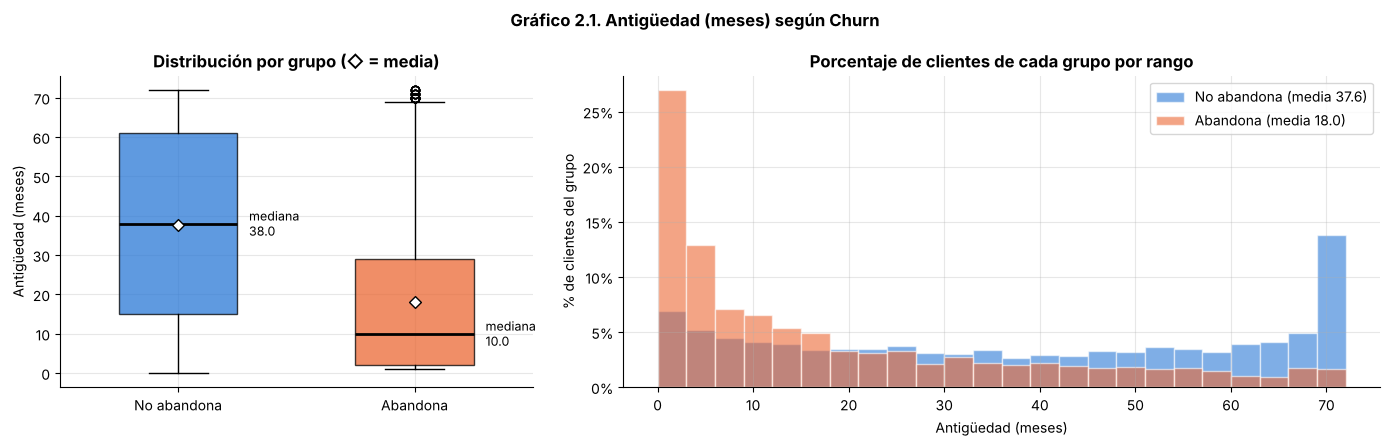

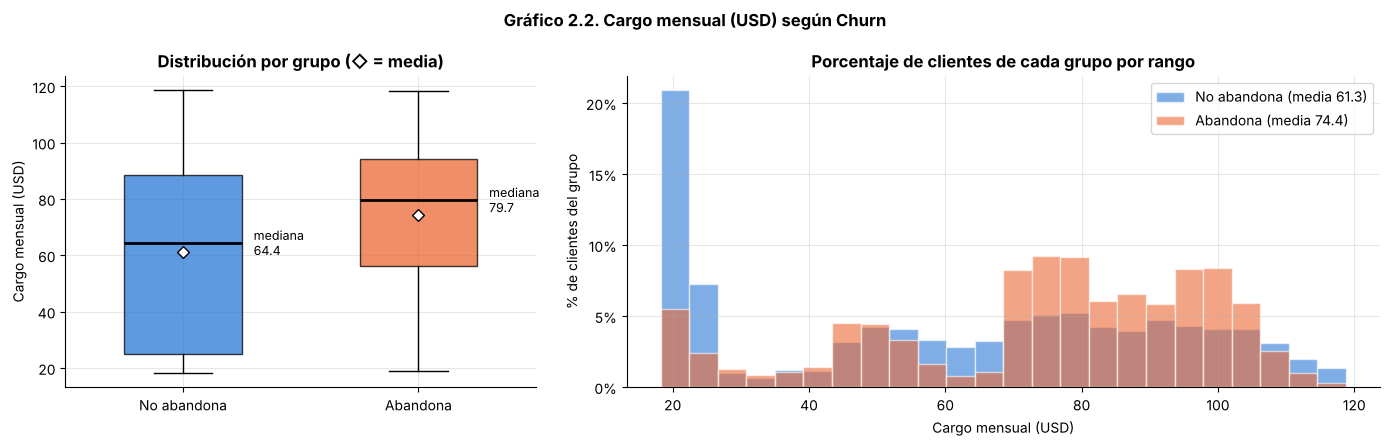

In [13]:
etiquetas = {"tenure": "Antigüedad (meses)", "MonthlyCharges": "Cargo mensual (USD)"}
for i, col in enumerate(["tenure", "MonthlyCharges"], start=1):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
    datos = [df.loc[df["Churn"] == "No", col], df.loc[df["Churn"] == "Yes", col]]
    bp = a1.boxplot(datos, tick_labels=["No abandona", "Abandona"], patch_artist=True, widths=0.5,
                    medianprops={"color": "black", "lw": 2})
    for patch, colr in zip(bp["boxes"], [COLOR_NO, COLOR_SI]):
        patch.set_facecolor(colr); patch.set_alpha(0.75)
    for x, d in zip([1, 2], datos):
        a1.text(x + 0.3, d.median(), f"mediana\n{d.median():.1f}", va="center", fontsize=9)
        a1.scatter(x, d.mean(), marker="D", color="white", edgecolor="black", zorder=3)
    a1.set_title("Distribución por grupo (◇ = media)"); a1.set_ylabel(etiquetas[col])
    bins = np.linspace(df[col].min(), df[col].max(), 25)
    for d, colr, lab in zip(datos, [COLOR_NO, COLOR_SI], ["No abandona", "Abandona"]):
        a2.hist(d, bins=bins, weights=np.ones(len(d)) / len(d) * 100, alpha=0.6, color=colr,
                label=f"{lab} (media {d.mean():.1f})", edgecolor="white")
    a2.set_title("Porcentaje de clientes de cada grupo por rango")
    a2.set_xlabel(etiquetas[col]); a2.set_ylabel("% de clientes del grupo")
    a2.yaxis.set_major_locator(mtick.MultipleLocator(5)); a2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); a2.legend()
    fig.suptitle(f"Gráfico 2.{i}. {etiquetas[col]} según Churn", fontweight="bold")
    plt.tight_layout(); plt.savefig(IMG + f"g2_{i}_{col}_vs_churn.png", dpi=130); plt.show()

**Observación (respaldada con métricas):**
- **Antigüedad:** quienes abandonan llevan una **mediana de 10 meses** con la empresa frente a **38 meses** de quienes se quedan (medias 18,0 vs 37,6). La moda de quienes se van es **1 mes**: el abandono se concentra en el primer mes. Diferencia significativa (Mann-Whitney p ≈ 2,4e-208) con un **efecto mediano-grande** (rango-biserial r = −0,48).
- **Cargo mensual:** quienes abandonan pagan una **mediana de USD 79,65** frente a USD 64,43 de quienes se quedan (medias 74,4 vs 61,3), y con menor dispersión (desv. 24,7 vs 31,1). La moda de quienes se quedan es USD 20,05 (planes solo teléfono). Diferencia significativa (p ≈ 3,3e-54) con efecto pequeño-mediano (r = 0,24). Ojo: la relación no es lineal (ver deciles en 5.5).
- **Cargo total:** menor en quienes se van (mediana USD 703,55 vs 1.679,52), (r = −0,30), pero es consecuencia de su menor antigüedad, no un factor independiente.

### 5.3 Variables categóricas vs. Churn

Un gráfico por variable. Se usa **barra horizontal con la tasa de churn de cada categoría** (en vez de barras apiladas al 100%), con el número de clientes de cada categoría y una línea de referencia en la tasa global (26,5%). Así se lee directamente cuánto más (o menos) abandona cada grupo.

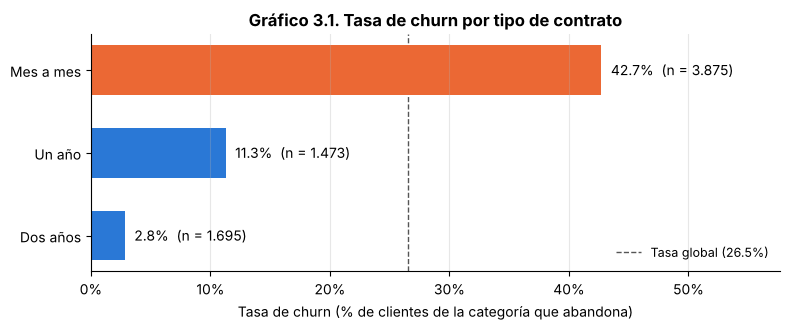

,n,tasa
Contract,,
Two year,1695,2.8
One year,1473,11.3
Month-to-month,3875,42.7


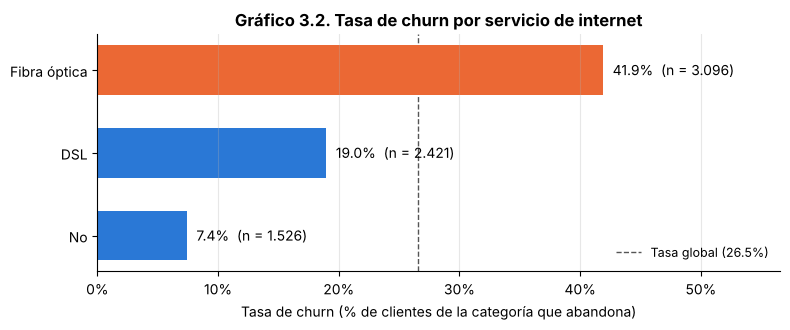

,n,tasa
InternetService,,
No,1526,7.4
DSL,2421,19.0
Fiber optic,3096,41.9


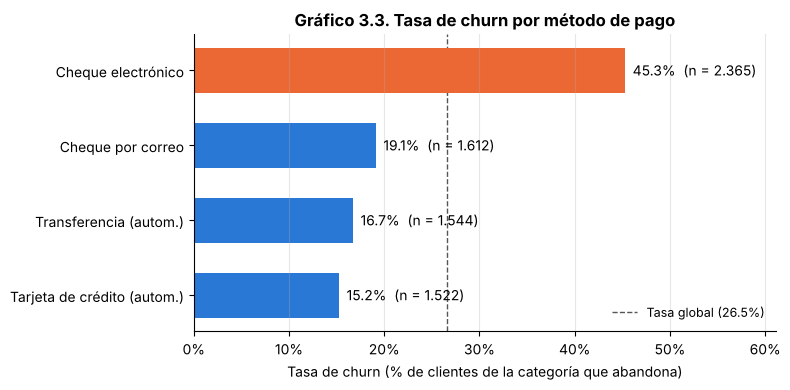

,n,tasa
PaymentMethod,,
Credit card (automatic),1522,15.2
Bank transfer (automatic),1544,16.7
Mailed check,1612,19.1
Electronic check,2365,45.3


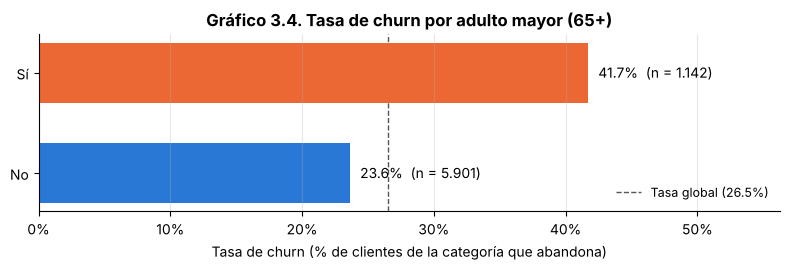

,n,tasa
SeniorCitizen,,
0,5901,23.6
1,1142,41.7


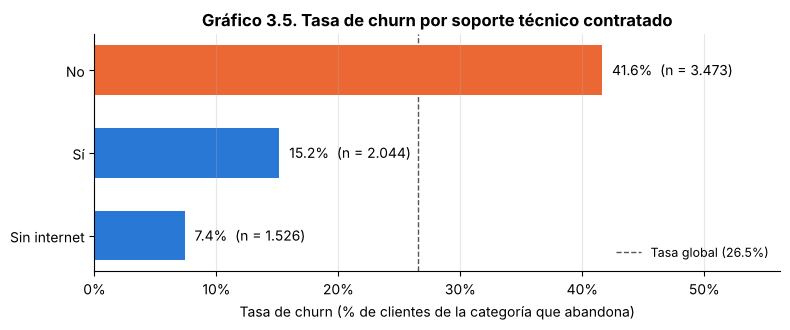

,n,tasa
TechSupport,,
No internet service,1526,7.4
Yes,2044,15.2
No,3473,41.6


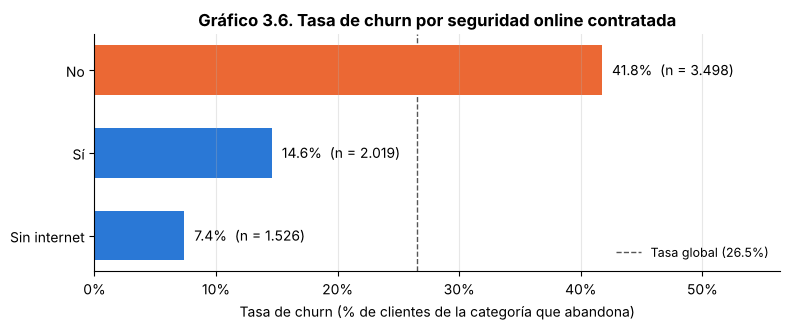

,n,tasa
OnlineSecurity,,
No internet service,1526,7.4
Yes,2019,14.6
No,3498,41.8


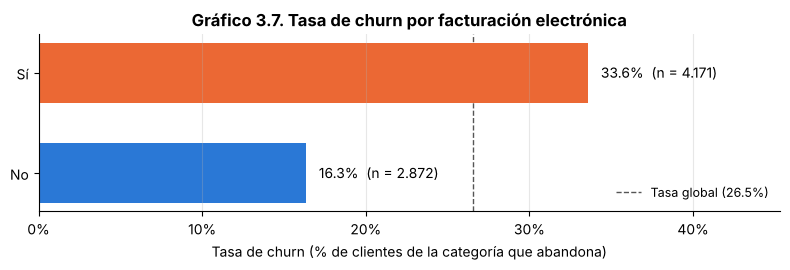

,n,tasa
PaperlessBilling,,
No,2872,16.3
Yes,4171,33.6


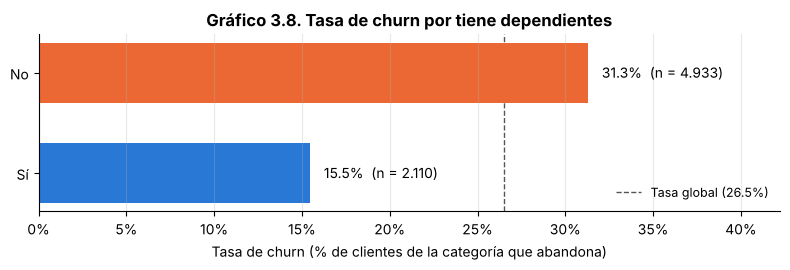

,n,tasa
Dependents,,
Yes,2110,15.5
No,4933,31.3


In [14]:
tasa_global = (df["Churn"] == "Yes").mean() * 100
nombres = {
    "Contract": "Tipo de contrato", "InternetService": "Servicio de internet",
    "PaymentMethod": "Método de pago", "SeniorCitizen": "Adulto mayor (65+)",
    "TechSupport": "Soporte técnico contratado", "OnlineSecurity": "Seguridad online contratada",
    "PaperlessBilling": "Facturación electrónica", "Dependents": "Tiene dependientes",
}
traduccion = {"Month-to-month": "Mes a mes", "One year": "Un año", "Two year": "Dos años",
              "Fiber optic": "Fibra óptica", "No": "No", "Yes": "Sí", 0: "No", 1: "Sí",
              "Electronic check": "Cheque electrónico", "Mailed check": "Cheque por correo",
              "Bank transfer (automatic)": "Transferencia (autom.)",
              "Credit card (automatic)": "Tarjeta de crédito (autom.)",
              "No internet service": "Sin internet", "DSL": "DSL"}

def grafico_tasa(col, num):
    t = df.groupby(col)["Churn"].agg(n="count", tasa=lambda s: (s == "Yes").mean() * 100)
    t = t.sort_values("tasa")
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(t) + 1.6))
    colores = [COLOR_SI if v > tasa_global else COLOR_NO for v in t["tasa"]]
    ax.barh([str(traduccion.get(i, i)) for i in t.index], t["tasa"], color=colores, height=0.6)
    for y, (v, n) in enumerate(zip(t["tasa"], t["n"])):
        ax.text(v + 0.8, y, f"{v:.1f}%  (n = {n:,})".replace(",", "."), va="center", fontsize=10)
    ax.axvline(tasa_global, color="#555555", ls="--", lw=1, zorder=0, label=f"Tasa global ({tasa_global:.1f}%)")
    ax.legend(loc="lower right", fontsize=9, frameon=False)
    ax.set_xlim(0, max(t["tasa"].max() * 1.35, tasa_global * 1.5))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_xlabel("Tasa de churn (% de clientes de la categoría que abandona)")
    ax.set_title(f"Gráfico 3.{num}. Tasa de churn por {nombres[col].lower()}")
    ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.savefig(IMG + f"g3_{num}_{col}.png", dpi=130); plt.show()
    return t.round(1)

for k, col in enumerate(nombres, start=1):
    display(grafico_tasa(col, k))

**Observaciones (tasa de churn por categoría; global 26,5%):**
- **Contrato:** mes a mes **42,7%** vs un año 11,3% y dos años **2,8%**. Un cliente mes a mes abandona ~15 veces más que uno con contrato de dos años.
- **Internet:** fibra óptica **41,9%** vs DSL 19,0% y sin internet 7,4%.
- **Método de pago:** cheque electrónico **45,3%**, más del doble que los pagos automáticos (15,2–16,7%).
- **Adulto mayor:** 41,7% vs 23,6% del resto.
- **Servicios de protección:** sin soporte técnico 41,6% vs 15,2% con soporte; sin seguridad online 41,8% vs 14,6%. Los servicios adicionales se asocian a mayor retención.
- **Facturación electrónica:** 33,6% vs 16,3%. **Dependientes:** sin dependientes 31,3% vs 15,5%.

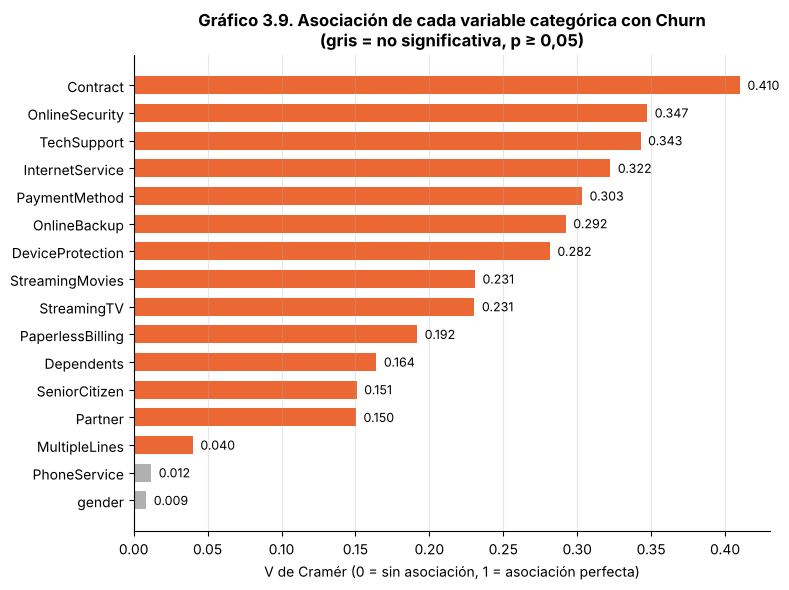

,variable,V de Cramér,chi2,p-valor
13,Contract,0.4101,1184.5966,0.0000
7,OnlineSecurity,0.3474,849.9990,0.0000
10,TechSupport,0.3429,828.1971,0.0000
6,InternetService,0.3225,732.3096,0.0000
15,PaymentMethod,0.3034,648.1423,0.0000
8,OnlineBackup,0.2923,601.8128,0.0000
9,DeviceProtection,0.2816,558.4194,0.0000
12,StreamingMovies,0.2310,375.6615,0.0000
11,StreamingTV,0.2305,374.2039,0.0000
14,PaperlessBilling,0.1918,258.2776,0.0000


In [15]:
# Fuerza de asociación de TODAS las variables categóricas con Churn: V de Cramér + chi-cuadrado
cat_cols = [c for c in df.columns if c not in ["customerID", "Churn"] + num_cols]
filas = []
for c in cat_cols:
    ct = pd.crosstab(df[c], df["Churn"])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    filas.append([c, association(ct, method="cramer"), chi2, p])
cramer = pd.DataFrame(filas, columns=["variable", "V de Cramér", "chi2", "p-valor"]).sort_values("V de Cramér", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(cramer["variable"][::-1], cramer["V de Cramér"][::-1],
        color=[COLOR_SI if p < 0.05 else "#b0b0b0" for p in cramer["p-valor"][::-1]], height=0.65)
for y, v in enumerate(cramer["V de Cramér"][::-1]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("V de Cramér (0 = sin asociación, 1 = asociación perfecta)")
ax.set_title("Gráfico 3.9. Asociación de cada variable categórica con Churn\n(gris = no significativa, p ≥ 0,05)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(IMG + "g3_9_cramer_v.png", dpi=130); plt.show()
cramer.round(4)

**Observación:** el **contrato** es la variable categórica más asociada al churn (V = 0,41), seguida de seguridad online, soporte técnico, tipo de internet y método de pago (V entre 0,30 y 0,35). **`gender` (V = 0,009, p = 0,49) y `PhoneService` (p = 0,34) no tienen relación significativa** con el abandono: el género no aporta información y su uso solo agregaría riesgo de discriminación (ver Sección 7).

### 5.4 Correlación (con el coeficiente adecuado a cada tipo de variable)

| Par de variables | Coeficiente usado | Por qué |
|---|---|---|
| Numérica vs numérica | **Spearman** | Las variables no son normales (5.2) y la relación esperada es monótona; Pearson supone normalidad y linealidad. |
| Numérica vs Churn (binaria) | **Punto-biserial** y **Spearman** | La punto-biserial es la correlación específica para una variable dicotómica; Spearman se reporta como respaldo robusto a la no normalidad. |
| Categórica vs Churn | **V de Cramér** | Ambas son nominales (ya calculado en 5.3). |

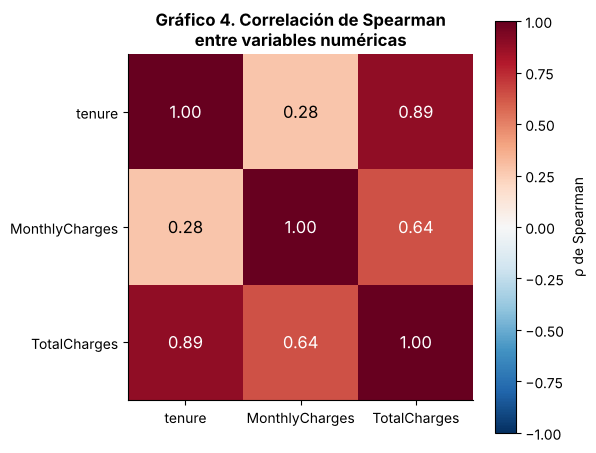

Spearman entre numéricas:
                 tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.276         0.890
MonthlyCharges   0.276           1.000         0.638
TotalCharges     0.890           0.638         1.000 

Pearson (solo como comparación):
                 tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.248         0.826
MonthlyCharges   0.248           1.000         0.651
TotalCharges     0.826           0.651         1.000 

Correlación de cada numérica con Churn:
                 punto-biserial  Spearman  p-valor (Spearman)
tenure                 -0.3522   -0.3671                 0.0
MonthlyCharges          0.1934    0.1847                 0.0
TotalCharges           -0.1983   -0.2300                 0.0


In [16]:
spearman = df[num_cols].corr(method="spearman")
pearson = df[num_cols].corr(method="pearson")
y_bin = (df["Churn"] == "Yes").astype(int)
corr_obj = pd.DataFrame({
    "punto-biserial": [stats.pointbiserialr(y_bin, df[c])[0] for c in num_cols],
    "Spearman": [stats.spearmanr(y_bin, df[c])[0] for c in num_cols],
    "p-valor (Spearman)": [stats.spearmanr(y_bin, df[c])[1] for c in num_cols],
}, index=num_cols)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(spearman, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(3), num_cols); ax.set_yticks(range(3), num_cols)
for i in range(3):
    for j in range(3):
        v = spearman.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > 0.6 else "black", fontsize=12)
ax.grid(False)
fig.colorbar(im, ax=ax, label="ρ de Spearman")
ax.set_title("Gráfico 4. Correlación de Spearman\nentre variables numéricas")
plt.tight_layout(); plt.savefig(IMG + "g4_correlacion_spearman.png", dpi=130); plt.show()

print("Spearman entre numéricas:\n", spearman.round(3), "\n")
print("Pearson (solo como comparación):\n", pearson.round(3), "\n")
print("Correlación de cada numérica con Churn:\n", corr_obj.round(4))

**Observación:**
- `tenure` y `TotalCharges` tienen ρ de Spearman = **0,89**: casi la misma información (TotalCharges ≈ tenure × MonthlyCharges, confirmado en 4.1). Se evaluará su redundancia en el modelamiento.
- Con Churn: `tenure` tiene la correlación más fuerte y **negativa** (punto-biserial −0,35; Spearman −0,37): a mayor antigüedad, menos abandono. `MonthlyCharges` es **positiva y débil** (0,19). `TotalCharges` es negativa y débil (−0,20 / −0,23). Todas significativas (p < 0,001).

### 5.5 Comparación entre el primer y el último decil

Siguiendo la sugerencia del docente, se divide a los clientes en 10 grupos de igual tamaño (deciles) según **cargo mensual** y según **antigüedad**, y se comparan el decil 1 (D1) y el decil 10 (D10) en tasa de churn y en composición demográfica y contractual. Sirve para ver diferencias de comportamiento entre extremos y detectar si un grupo demográfico queda sobrerrepresentado en un extremo (posible fuente de sesgo).

=== Deciles de MonthlyCharges ===


,rango,churn,adulto_mayor,mujer,mes_a_mes,fibra,cheque_electronico
D1,18–20,8.7%,3.3%,47.7%,38.6%,0.0%,7.9%
D10,103–119,24.7%,25.0%,51.5%,29.5%,100.0%,37.6%
D10 − D1 (pp),—,+16.0,+21.7,+3.8,-9.1,+100.0,+29.6


=== Deciles de tenure ===


,rango,churn,adulto_mayor,mujer,mes_a_mes,fibra,cheque_electronico
D1,0–2,61.0%,13.5%,47.4%,96.7%,39.4%,47.8%
D10,69–72,3.8%,16.2%,48.8%,2.0%,42.3%,13.9%
D10 − D1 (pp),—,-57.2,+2.7,+1.4,-94.8,+2.8,-33.9


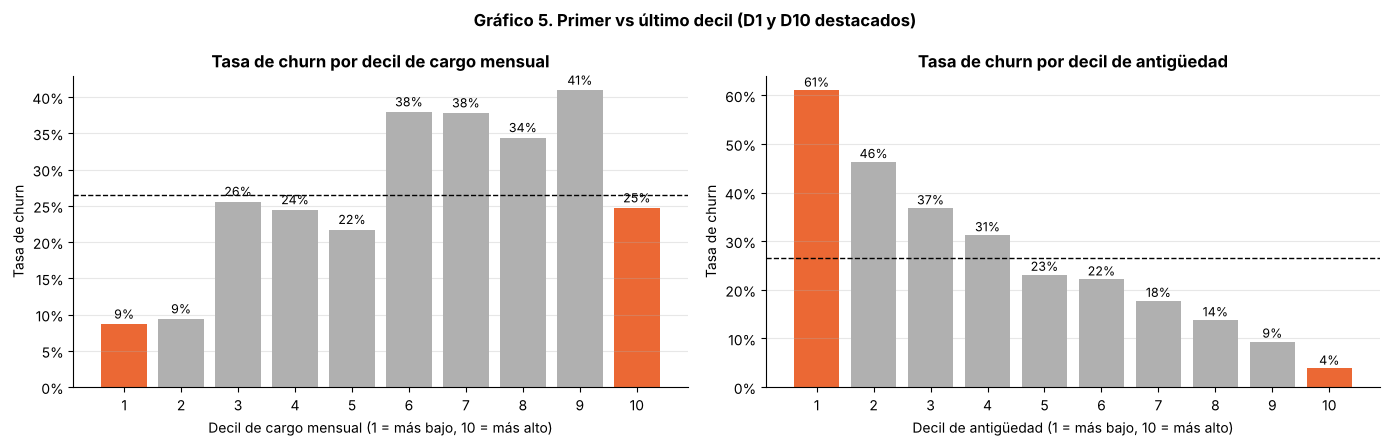

In [17]:
def comparar_deciles(var):
    dec = pd.qcut(df[var].rank(method="first"), 10, labels=range(1, 11))
    aux = df.assign(decil=dec,
                    churn=(df["Churn"] == "Yes"), adulto_mayor=df["SeniorCitizen"] == 1,
                    mujer=df["gender"] == "Female", mes_a_mes=df["Contract"] == "Month-to-month",
                    fibra=df["InternetService"] == "Fiber optic",
                    cheque_electronico=df["PaymentMethod"] == "Electronic check")
    g = aux.groupby("decil", observed=True).agg(
        rango=(var, lambda s: f"{s.min():.0f}–{s.max():.0f}"),
        churn=("churn", "mean"), adulto_mayor=("adulto_mayor", "mean"), mujer=("mujer", "mean"),
        mes_a_mes=("mes_a_mes", "mean"), fibra=("fibra", "mean"), cheque_electronico=("cheque_electronico", "mean"))
    return g

for var in ["MonthlyCharges", "tenure"]:
    g = comparar_deciles(var)
    comp = g.loc[[1, 10]].copy()
    num = ["churn", "adulto_mayor", "mujer", "mes_a_mes", "fibra", "cheque_electronico"]
    comp.loc["D10 − D1 (pp)"] = ["—"] + [f"{v:+.1f}" for v in (g.loc[10, num] - g.loc[1, num]) * 100]
    comp[num] = comp[num].map(lambda v: f"{v*100:.1f}%" if isinstance(v, float) and abs(v) <= 1 else v)
    comp.index = ["D1", "D10", "D10 − D1 (pp)"]
    print(f"=== Deciles de {var} ===")
    display(comp)

# Tasa de churn en los 10 deciles de cada variable
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, var, et in zip(axes, ["MonthlyCharges", "tenure"], ["cargo mensual", "antigüedad"]):
    g = comparar_deciles(var)
    ax.bar(g.index.astype(int), g["churn"] * 100, color=[COLOR_SI if i in (1, 10) else "#b0b0b0" for i in g.index])
    for x, v in zip(g.index.astype(int), g["churn"] * 100):
        ax.text(x, v + 0.8, f"{v:.0f}%", ha="center", fontsize=9)
    ax.axhline(tasa_global, color="black", ls="--", lw=1)
    ax.set_xticks(range(1, 11)); ax.set_xlabel(f"Decil de {et} (1 = más bajo, 10 = más alto)")
    ax.set_ylabel("Tasa de churn"); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_title(f"Tasa de churn por decil de {et}"); ax.grid(axis="x", visible=False)
fig.suptitle("Gráfico 5. Primer vs último decil (D1 y D10 destacados)", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "g5_deciles.png", dpi=130); plt.show()

**Observación:**
- **Cargo mensual:** D10 (USD 102,6–118,75) abandona **24,7%** vs **8,7%** en D1 (USD 18,25–20,05). Pero la relación **no es lineal**: el churn más alto está en los deciles 6 a 9 (USD 70–103), entre **34% y 41%**, y baja en el D10. La razón está en el contrato: en los deciles 6–9 entre 63% y 69% de los clientes es mes a mes, mientras que en el D10 solo 29,5% (los que más pagan suelen tener contratos largos). Es decir, "pagar más" solo se asocia a más abandono cuando va junto con contrato mes a mes.
- El D10 de cargo mensual es 100% fibra óptica y tiene **25,0% de adultos mayores vs 3,3% en D1**: los adultos mayores se concentran en los planes caros.
- **Antigüedad:** relación monótona decreciente. D1 (0–2 meses) abandona **61,0%**; D10 (69–72 meses) solo **3,8%**. D1 es 96,7% mes a mes; D10 solo 2,0%.
- La proporción de mujeres es similar en ambos extremos (47–52%), es decir, el género **no** cambia entre deciles.
- **Implicancia de sesgo:** la mayor tasa de churn de los adultos mayores (5.3) puede deberse en parte a que contratan más fibra y planes caros. Si el modelo usara `SeniorCitizen` directamente, podría atribuir a la edad un efecto que es del plan. Esto se audita en el notebook 2 con los deciles de riesgo predicho.

## 6. Preparación y transformación de los datos

### 6.1 Corrección de tipos e imputación
Ya realizado en 4.1: `TotalCharges` a numérico e imputación de los 11 blancos con 0.

### 6.2 Eliminación de columnas
`customerID` es un identificador sin valor predictivo; se elimina.

In [18]:
df_prep = df.drop(columns=["customerID"]).copy()
df_prep.shape

(7043, 20)

### 6.3 Codificación de variables categóricas
- **Binarias (Yes/No, Female/Male):** mapeo explícito a 1/0 (más transparente que `LabelEncoder`, porque deja claro qué valor es 1).
- **Multinivel:** *one-hot encoding* con `drop_first=True`.
- **Corrección respecto a la EP1:** las 6 columnas `<servicio>_No internet service` y `MultipleLines_No phone service` son **idénticas** a `InternetService_No` y a `PhoneService = 0` (consistencia verificada en 4.1). Son información duplicada que genera **multicolinealidad perfecta** (problema para la Regresión Logística), así que se eliminan.

In [19]:
binarias = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
for c in binarias:
    df_prep[c] = df_prep[c].map({"Yes": 1, "No": 0})
df_prep["gender"] = df_prep["gender"].map({"Female": 1, "Male": 0})
df_prep = df_prep.rename(columns={"gender": "gender_Female"})

multinivel = ["MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaymentMethod"]
df_prep = pd.get_dummies(df_prep, columns=multinivel, drop_first=True, dtype=int)

# Verificar que las columnas redundantes son exactamente iguales antes de eliminarlas
redundantes = [c for c in df_prep.columns if c.endswith("_No internet service")]
for c in redundantes:
    assert (df_prep[c] == df_prep["InternetService_No"]).all()
assert (df_prep["MultipleLines_No phone service"] == 1 - df_prep["PhoneService"]).all()
redundantes.append("MultipleLines_No phone service")
df_prep = df_prep.drop(columns=redundantes)
print(f"Se eliminaron {len(redundantes)} columnas redundantes: {redundantes}")
print(f"Dimensiones finales: {df_prep.shape}")
df_prep.head()

Se eliminaron 7 columnas redundantes: ['OnlineSecurity_No internet service', 'OnlineBackup_No internet service', 'DeviceProtection_No internet service', 'TechSupport_No internet service', 'StreamingTV_No internet service', 'StreamingMovies_No internet service', 'MultipleLines_No phone service']
Dimensiones finales: (7043, 24)


,gender_Female,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,0,1,0,1,0,1,29.85,29.85,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,34,1,0,56.95,1889.50,0,0,0,0,1,0,1,0,0,0,1,0,0,0,1
2,0,0,0,0,2,1,1,53.85,108.15,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1
3,0,0,0,0,45,0,0,42.30,1840.75,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0
4,1,0,0,0,2,1,1,70.70,151.65,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0


### 6.4 Elección del método de escalado (según la forma de cada variable)

| Escalador | Cuándo corresponde | Fórmula |
|---|---|---|
| `StandardScaler` | Datos aproximadamente **simétricos/normales** | (x − media) / desv. estándar |
| `RobustScaler` | Datos **asimétricos** o con atípicos (usa mediana e IQR, no se distorsiona con la cola) | (x − mediana) / IQR |
| `MinMaxScaler` | Datos **acotados y de forma uniforme/aplanada** | (x − mín) / (máx − mín) → [0, 1] |

Con la forma medida en 5.2:

| Variable | Forma observada | Escalador elegido |
|---|---|---|
| `tenure` | skew 0,24, curtosis −1,39 (aplanada, dos picos en los extremos), acotada 0–72, no normal | **MinMaxScaler** |
| `MonthlyCharges` | skew −0,22, curtosis −1,26 (aplanada y bimodal), acotada 18–119, no normal | **MinMaxScaler** |
| `TotalCharges` | skew **0,96** (asimétrica a la derecha, cola larga) | **RobustScaler** |

Ninguna variable cumple el supuesto de normalidad, por lo que `StandardScaler` (usado en la EP1) **no** era la opción adecuada.

**Corrección importante respecto a la EP1:** en la EP1 el escalador se ajustó con todo el dataset **antes** de dividir en train/test, lo que filtra información del conjunto de prueba (*data leakage*). Ahora primero se divide y el escalador se ajusta **solo con train**.

### 6.5 División train/test estratificada y escalado sin fuga de información

In [20]:
X = df_prep.drop(columns=["Churn"])
y = df_prep["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Churn en train: {y_train.mean():.4f} | Churn en test: {y_test.mean():.4f}")

minmax_cols, robust_cols = ["tenure", "MonthlyCharges"], ["TotalCharges"]
mm, rb = MinMaxScaler(), RobustScaler()
X_train_esc, X_test_esc = X_train.copy(), X_test.copy()
X_train_esc[minmax_cols] = mm.fit_transform(X_train[minmax_cols])   # fit SOLO en train
X_test_esc[minmax_cols] = mm.transform(X_test[minmax_cols])         # test solo se transforma
X_train_esc[robust_cols] = rb.fit_transform(X_train[robust_cols])
X_test_esc[robust_cols] = rb.transform(X_test[robust_cols])
X_train_esc[num_cols].describe().round(3)

Train: 5634 | Test: 1409
Churn en train: 0.2654 | Churn en test: 0.2654


,tenure,MonthlyCharges,TotalCharges
count,5634.000,5634.000,5634.000
mean,0.451,0.464,0.263
std,0.341,0.300,0.664
min,0.000,0.000,-0.406
25%,0.125,0.172,-0.289
50%,0.403,0.519,0.000
75%,0.764,0.714,0.711
max,1.000,1.000,2.124


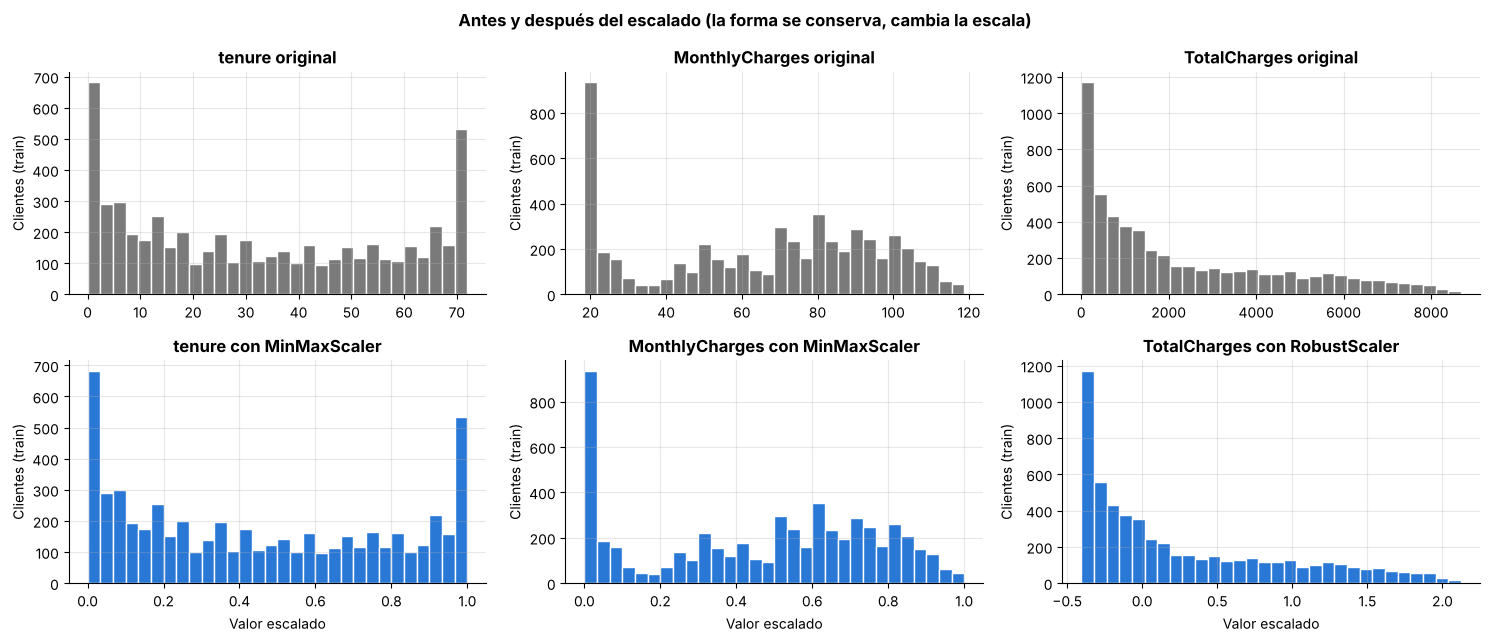

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for j, c in enumerate(num_cols):
    axes[0, j].hist(X_train[c], bins=30, color="#7a7a7a", edgecolor="white")
    axes[0, j].set_title(f"{c} original"); axes[0, j].set_ylabel("Clientes (train)")
    esc = "MinMax" if c in minmax_cols else "Robust"
    axes[1, j].hist(X_train_esc[c], bins=30, color=COLOR_NO, edgecolor="white")
    axes[1, j].set_title(f"{c} con {esc}Scaler"); axes[1, j].set_ylabel("Clientes (train)")
    axes[1, j].set_xlabel("Valor escalado")
fig.suptitle("Antes y después del escalado (la forma se conserva, cambia la escala)", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG + "escalado_antes_despues.png", dpi=130); plt.show()

**Resultado:** `tenure` y `MonthlyCharges` quedan en [0, 1]; `TotalCharges` queda centrada en su mediana (0) y medida en unidades de IQR, sin que la cola larga comprima al resto de los valores. La proporción de churn es la misma en train y test (26,5%) gracias a la estratificación.

### 6.6 Guardado del dataset limpio
Se guarda el dataset **limpio y codificado, sin escalar** (`data/telco_churn_limpio.csv`). El escalado no se guarda ya aplicado: en el notebook 2 se aplica dentro de un `Pipeline`, ajustándose solo con los datos de entrenamiento de cada partición de validación cruzada, para no filtrar información.

In [22]:
df_prep.to_csv("../data/telco_churn_limpio.csv", index=False)
print("Guardado data/telco_churn_limpio.csv:", df_prep.shape)

Guardado data/telco_churn_limpio.csv: (7043, 24)


## 7. Evaluación de sesgos, ética y privacidad

**Privacidad**
- El dataset no tiene identificadores directos (nombre, RUT, dirección, teléfono); `customerID` es un código sin significado externo. Además, los datos son **ficticios** (Sección 2), por lo que no hay riesgo real de reidentificación.
- En un caso real con clientes chilenos aplicaría la **Ley 19.628** sobre protección de la vida privada y la **Ley 21.719** que la actualiza: minimización de datos (usar solo lo necesario para el fin de retención), finalidad declarada al cliente y resguardo de los datos de facturación.

**Sesgo demográfico (medido, no solo enunciado)**
- **Género:** no tiene relación con el churn (V de Cramér 0,009, p = 0,49; 26,9% mujeres vs 26,2% hombres) y su proporción no cambia entre deciles. No aporta poder predictivo y sí riesgo de discriminación ⇒ **se excluirá del modelo** y solo se usará para auditar resultados.
- **Edad (SeniorCitizen):** los adultos mayores abandonan más (41,7% vs 23,6%), pero el análisis por deciles muestra que están **sobrerrepresentados en los planes caros** (25,0% en el D10 de cargo mensual vs 3,3% en el D1). Parte de su "riesgo" viene del plan, no de la edad. Se evaluará en el notebook 2 si el modelo los marca más como riesgo y si eso es justo (comparando su recall/precisión con el resto).

**Sesgo de representación**
- Datos de **una empresa ficticia en California**, un solo trimestre (Q3) y año no informado. No representan el mercado chileno ni la estacionalidad del año: los resultados no deben extrapolarse sin reentrenar con datos locales.

**Sesgo por desbalance de clases**
- 26,5% churn. Sin ajuste, el modelo tendería a predecir "no abandona". Se abordará con `class_weight="balanced"` y métricas como recall, precisión y F1.

**Uso responsable**
- El modelo es **apoyo a la decisión** para ofrecer beneficios de retención; nunca para perjudicar al cliente (por ejemplo, subir precios a quienes se predice que no se irán) ni para negar servicios.

## 8. Metodología CRISP-DM (avance en este notebook)

1. **Comprensión del negocio:** problema, objetivos y KPIs (Secciones 2–3).
2. **Comprensión de los datos:** origen, calidad, consistencia y EDA (Secciones 2, 4, 5).
3. **Preparación de los datos:** limpieza, codificación, eliminación de redundancias, escalado justificado y partición sin fuga (Sección 6).
4. **Modelamiento**, 5. **Evaluación**, 6. **Despliegue:** notebook `02_Modelamiento_Churn.ipynb`.

## 9. Conclusiones

- Datos de buena calidad: único problema `TotalCharges` (11 blancos, imputados con 0), sin atípicos IQR y con categorías 100% consistentes.
- Churn de **26,5%** (desbalance 1 : 2,8).
- Factores de mayor riesgo, respaldados con métricas: **contrato mes a mes** (42,7%; V = 0,41), **baja antigüedad** (mediana 10 vs 38 meses; Spearman −0,37), **fibra óptica** (41,9%), **cheque electrónico** (45,3%), **sin soporte técnico / seguridad online** (~42%) y **cargos mensuales medios-altos** (mediana USD 79,65 vs 64,43; el pico de churn está entre USD 70 y 103, no en los planes más caros, que suelen tener contrato largo).
- `gender` y `PhoneService` no se asocian al churn.
- `TotalCharges` es redundante con `tenure` (ρ = 0,89).
- Escalado corregido según la forma de cada variable (MinMax para `tenure` y `MonthlyCharges`, Robust para `TotalCharges`) y aplicado sin fuga de información.